# Supplementary Analysis for the Manuscript

**Decoding Size-Resolved Particulate Matter Dynamics under Tropical Riverine
Conditions: An Interpretable Machine Learning Analysis of Hourly PM1, PM2.5, and
PM10 Variability in Pontianak, Indonesia**

Joko Sampurno and Irfana Diah Faryuni — Department of Physics, Faculty of
Mathematics and Natural Sciences, Universitas Tanjungpura, Pontianak, Indonesia

---

This notebook reproduces the complete analysis reported in the revised
manuscript and generates every quantity introduced during revision. It is
released together with the processed hourly series in support of the Data and
Code Availability statement.

### Correspondence between notebook sections and reviewer comments

| Section | Reviewer comment addressed |
|---|---|
| 1–2 | Reconciliation of the three record counts (R3.6); credibility of the reported temperature maximum (R3.7) |
| 3 | Feature construction; verification that `season_dry` is constant in the primary hold-out window (R4.2) |
| 4 | Equal-footing hyper-parameter search with early stopping (R3.3) |
| 5 | Coefficient of determination for all model–fraction combinations under both baseline conventions (R1.1, R3.2, R4.1) |
| 6 | Rolling-origin cross-validation over ten seeds; paired per-fold contrasts between learners (R1.1, R3.3) |
| 7 | Sensitivity of the results to screening of radiatively affected hours (R3.7) |
| 8 | Out-of-fold SHAP attribution with bootstrap intervals on the size-dependent shares (R3.4, R4.2) |
| 9 | Regeneration of the beeswarm figure for all three fractions, ordered by mean absolute SHAP (R3.5, R3.10) |
| 10 | Separation of the wet-scavenging and instrumental explanations for the 88–90 % humidity feature (R1.3, R3.9) |
| 11 | Permutation control for the `dow` attribution (R3.11) |
| 12 | Export of manuscript-ready tables |

### Usage

Execute the cells in order. Section 1 prompts for the data file, Section 1b maps
the column names automatically, and Section 1c verifies the time-zone
convention before any analysis proceeds. Outputs are written to `outputs/`.

Runtime is dominated by Section 6, which fits 450 models, and by the attribution
step in Section 8; together these take roughly 30–60 minutes on a Colab CPU
runtime. For a first pass, reduce `N_SEEDS` to 3 in Section 1 and restore it to 10
for the values reported in the manuscript. If Section 8 is slow or the session
runs out of memory, lower `SHAP_MAX_ROWS`.

## 1. Environment and data ingestion

Run the cell below and select the data file from your computer when prompted.
Comma-separated, tab-separated and Excel workbooks are all accepted; the
delimiter is inferred automatically. Column names are mapped in Section 1b, so
the file does not need to be prepared beforehand.

Files uploaded in this way persist only for the duration of the Colab session.
For repeated use it is more convenient to upload the series once to Google Drive
and mount it with `from google.colab import drive; drive.mount('/content/drive')`,
setting `DATA_PATH` to the corresponding path.

In [1]:
!pip -q install shap==0.46.0 lightgbm xgboost scikit-learn pandas numpy matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 43.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, json, warnings, itertools, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

os.makedirs("outputs", exist_ok=True)

# --------------------------------------------------------------- PARAMETERS
TZ_SHIFT_HOURS = 7        # UTC to Western Indonesian Time. Set to 0 if the
                          #   timestamps are already local. Section 1c verifies
                          #   this choice against the expected diurnal cycle.
SPLIT_FRAC     = 0.80     # fraction of the record used for the primary hold-out
N_FOLDS        = 5        # rolling-origin (expanding-window) folds
N_SEEDS        = 10       # random seeds per fold; reduce to 3 for a trial run
TEMP_FLAG      = 38.0     # threshold for flagging radiatively affected hours (deg C)
SHAP_MAX_ROWS  = 800      # rows sampled per fold for SHAP; None uses every row.
                          #   TreeExplainer cost on a random forest scales as
                          #   rows x trees x depth^2, so an uncapped call on a
                          #   deep 800-tree ensemble is slow and memory-hungry.
                          #   Pooled over five folds this still yields ~4,000
                          #   attribution rows, ample for the bootstrap in
                          #   Section 8. Raise it if memory allows.
TARGETS        = ["pm1", "pm25", "pm10"]
RANDOM_STATE   = 42

COLMAP = None             # None triggers automatic detection in Section 1b.
                          # Specify explicitly if detection fails, for example:
                          # COLMAP = {"datetime": "Timestamp", "pm1": "PM1.0",
                          #           "pm25": "PM2.5", "pm10": "PM10",
                          #           "temp_c": "Temp", "rh": "Humidity",
                          #           "pressure": "Pressure"}

# ------------------------------------------------------------- FILE UPLOAD
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    print("Select the data file (.csv, .txt, .xlsx or .xls) ...")
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("No file was uploaded. Re-run this cell.")
    DATA_PATH = list(uploaded.keys())[0]
    if len(uploaded) > 1:
        print(f"Several files uploaded; using the first: {DATA_PATH}")
else:
    DATA_PATH = "data_raw.csv"      # outside Colab, place the file in the working directory

print(f"\nFile       : {DATA_PATH}")
print(f"Size       : {os.path.getsize(DATA_PATH) / 1e6:.2f} MB")

ext = os.path.splitext(DATA_PATH)[1].lower()
if ext in (".xlsx", ".xls"):
    raw = pd.read_excel(DATA_PATH)
else:
    raw = pd.read_csv(DATA_PATH, sep=None, engine="python")   # delimiter inferred

print(f"Dimensions : {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"Columns    : {list(raw.columns)}")
raw.head()

Select the data file (.csv, .txt, .xlsx or .xls) ...


Saving data_raw.csv to data_raw.csv

File       : data_raw.csv
Size       : 1.10 MB
Dimensions : 6,182 rows x 64 columns
Columns    : ['Source', 'Device timezone', 'Datetime_start(UTC)', 'Datetime_end(UTC)', 'AQI US', 'AQI CN', 'PM2.5 (ug/m3)', 'PM10 (ug/m3)', 'PM1 (ug/m3)', 'CO2 (ppm)', 'CO (ug/m3)', 'TVOC (index)', 'NOx (index)', 'O3 (ug/m3)', 'NO2 (ug/m3)', 'Temperature (Celsius)', 'Temperature (Fahrenheit)', 'Humidity (%)', 'Outdoor PM2.5 (ug/m3)', 'HCHO (ppb)', 'TVOC (ppb)', 'Pressure (pascal)', 'Particle Count', 'Fan Speed Level', 'slot.1.co2', 'slot.1.pm1', 'slot.1.pm10', 'slot.1.pm25', 'slot.1.pc', 'slot.1.voc', 'slot.1.hcho', 'slot.1.o3', 'slot.1.co', 'slot.1.no2', 'slot.2.co2', 'slot.2.pm1', 'slot.2.pm10', 'slot.2.pm25', 'slot.2.pc', 'slot.2.voc', 'slot.2.hcho', 'slot.2.o3', 'slot.2.co', 'slot.2.no2', 'slot.3.co2', 'slot.3.pm1', 'slot.3.pm10', 'slot.3.pm25', 'slot.3.pc', 'slot.3.voc', 'slot.3.hcho', 'slot.3.o3', 'slot.3.co', 'slot.3.no2', 'slot.4.co2', 'slot.4.pm1', 'slot.4.p

,Source,Device timezone,Datetime_start(UTC),Datetime_end(UTC),AQI US,AQI CN,PM2.5 (ug/m3),PM10 (ug/m3),PM1 (ug/m3),CO2 (ppm),...,slot.4.co2,slot.4.pm1,slot.4.pm10,slot.4.pm25,slot.4.pc,slot.4.voc,slot.4.hcho,slot.4.o3,slot.4.co,slot.4.no2
0,6ucbhp1wgum,Asia/Jakarta UTC+07:00,10/13/2025 11:00,10/13/2025 11:59,75,31,22,26,19,NaN,...,NaN,NaN,23,21,NaN,NaN,NaN,NaN,NaN,NaN
1,6ucbhp1wgum,Asia/Jakarta UTC+07:00,10/13/2025 12:00,10/13/2025 12:59,66,24,17,20,15,NaN,...,NaN,NaN,18,16,NaN,NaN,NaN,NaN,NaN,NaN
2,6ucbhp1wgum,Asia/Jakarta UTC+07:00,10/13/2025 13:00,10/13/2025 13:59,66,24,17,20,15,NaN,...,NaN,NaN,17,16,NaN,NaN,NaN,NaN,NaN,NaN
3,6ucbhp1wgum,Asia/Jakarta UTC+07:00,10/13/2025 14:00,10/13/2025 14:59,64,23,16,19,13,NaN,...,NaN,NaN,16,14,NaN,NaN,NaN,NaN,NaN,NaN
4,6ucbhp1wgum,Asia/Jakarta UTC+07:00,10/13/2025 15:00,10/13/2025 15:59,62,21,15,19,13,NaN,...,NaN,NaN,17,14,NaN,NaN,NaN,NaN,NaN,NaN


### 1b. Column mapping

Column names differ between instrument export formats, so the cell below matches
them to the seven canonical names used throughout. **The resulting mapping should
be inspected before proceeding.** If any assignment is incorrect, specify
`COLMAP` explicitly in Section 1 and re-run from there.

Timestamps split across separate date and time columns are combined
automatically. Normalisation deliberately preserves the decimal point, since it
is the only character distinguishing `PM1.0 (µg/m³)` from `PM10 (µg/m³)`;
removing it would collapse the two headers into an identical string and cause one
channel to be lost without warning.

In [3]:
ALIASES = {
    "datetime": ["datetime", "datetimeutc", "datetimelocal", "timestamp", "time",
                 "date", "localtime", "observedat", "waktu", "tanggal"],
    "pm10":     ["pm10", "pm10ugm3", "pm10conc"],
    "pm25":     ["pm2.5", "pm25", "pm2.5ugm3", "pm25ugm3", "pm25conc", "pm2p5"],
    "pm1":      ["pm1.0", "pm1", "pm1.0ugm3", "pm1ugm3", "pm1conc", "pm1p0"],
    "temp_c":   ["tempc", "temp", "temperature", "temperaturec", "airtemp", "suhu"],
    "rh":       ["rh", "humidity", "relativehumidity", "hum", "kelembapan"],
    "pressure": ["pressure", "press", "pres", "barometricpressure", "hpa", "tekanan"],
}
# PM10 is resolved before PM2.5 and PM1 so that a "PM10" header is not claimed by
# the shorter "PM1" alias.
ORDER = ["datetime", "pm10", "pm25", "pm1", "temp_c", "rh", "pressure"]
FINAL = ["datetime", "pm1", "pm25", "pm10", "temp_c", "rh", "pressure"]


def norm(x):
    """Lower-case and strip punctuation, retaining the decimal point."""
    return re.sub(r"[^a-z0-9.]", "", str(x).lower()).strip(".")


def detect(cols):
    """Map dataset columns to canonical names; exact matches take precedence."""
    pool = [(norm(c), c) for c in cols]        # list, not dict, so duplicates survive
    out, taken = {}, set()
    for canon in ORDER:
        for alias in ALIASES[canon]:
            hit = next((o for n, o in pool if n == alias and o not in taken), None)
            if hit is None and len(alias) > 3:
                hit = next((o for n, o in pool
                            if n.startswith(alias) and o not in taken), None)
            if hit is not None:
                out[canon] = hit
                taken.add(hit)
                break
    return out


collisions = {}
for c in raw.columns:
    collisions.setdefault(norm(c), []).append(c)
collisions = {k: v for k, v in collisions.items() if len(v) > 1}
if collisions:
    print("Warning: the following columns are indistinguishable after normalisation:")
    for k, v in collisions.items():
        print(f"  {k}: {v}")
    print("Specify COLMAP explicitly in Section 1 to remove the ambiguity.\n")

if COLMAP is None:
    COLMAP = detect(raw.columns)
    print("Automatic detection:")
else:
    print("User-specified mapping:")

for canon in FINAL:
    got = COLMAP.get(canon)
    print(f"  {canon:<9} <- {got if got else '*** NOT FOUND ***'}")

# timestamps split across separate date and time columns
if "datetime" not in COLMAP:
    dcol = next((c for c in raw.columns if norm(c) in ("date", "tanggal")), None)
    tcol = next((c for c in raw.columns if norm(c) in ("time", "hour", "jam")), None)
    if dcol and tcol:
        raw["_datetime"] = (raw[dcol].astype(str).str.strip() + " "
                            + raw[tcol].astype(str).str.strip())
        COLMAP["datetime"] = "_datetime"
        print(f"\n  -> combined from '{dcol}' and '{tcol}'")

missing = [c for c in FINAL if c not in COLMAP]
if missing:
    raise KeyError(f"Unmapped columns: {missing}. Specify COLMAP explicitly in Section 1.")

raw = raw.rename(columns={v: k for k, v in COLMAP.items()})[FINAL]

raw["datetime"] = pd.to_datetime(raw["datetime"], errors="coerce", dayfirst=False)
n_bad = int(raw["datetime"].isna().sum())
if n_bad:
    print(f"\nWarning: {n_bad:,} timestamps could not be parsed and were discarded.")
    print("If this count is large, the dates are probably day-first (31/12/2025);")
    print("set dayfirst=True above and re-run this cell.")
raw = raw.dropna(subset=["datetime"])

for c in ["pm1", "pm25", "pm10", "temp_c", "rh", "pressure"]:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")

# Pressure is exported in pascal by some firmware and in hectopascal by others.
# The manuscript reports hectopascal, so convert when the magnitude indicates pascal.
if raw["pressure"].median() > 10000:
    raw["pressure"] = raw["pressure"] / 100.0
    print("Pressure appears to be in pascal; converted to hectopascal.")

if TZ_SHIFT_HOURS:
    raw["datetime"] = raw["datetime"] + pd.Timedelta(hours=TZ_SHIFT_HOURS)
raw = raw.sort_values("datetime").reset_index(drop=True)

print(f"\nPeriod : {raw['datetime'].min()}  to  {raw['datetime'].max()}")
print(f"Rows   : {len(raw):,}")
print("\nMissing values by column:")
print(raw.isna().sum().to_string())
raw.head()

Automatic detection:
  datetime  <- Datetime_start(UTC)
  pm1       <- PM1 (ug/m3)
  pm25      <- PM2.5 (ug/m3)
  pm10      <- PM10 (ug/m3)
  temp_c    <- Temperature (Celsius)
  rh        <- Humidity (%)
  pressure  <- Pressure (pascal)
Pressure appears to be in pascal; converted to hectopascal.

Period : 2025-10-13 18:00:00  to  2026-06-29 23:00:00
Rows   : 6,182

Missing values by column:
datetime    0
pm1         0
pm25        0
pm10        0
temp_c      0
rh          0
pressure    0


,datetime,pm1,pm25,pm10,temp_c,rh,pressure
0,2025-10-13 18:00:00,19,22,26,31,72,1008.86
1,2025-10-13 19:00:00,15,17,20,31,71,1009.21
2,2025-10-13 20:00:00,15,17,20,30,71,1009.48
3,2025-10-13 21:00:00,13,16,19,30,71,1009.62
4,2025-10-13 22:00:00,13,15,19,29,71,1009.61


### 1c. Verification of the time-zone convention

The value of `TZ_SHIFT_HOURS` determines whether the diurnal structure reported
in Section 3.2 of the manuscript is correctly referenced to local solar time, and
it is worth confirming before proceeding. The manuscript reports a PM minimum in
the early afternoon, near 13:00 WIB, when the convective boundary layer is
deepest, and a broad maximum near 23:00 WIB.

If the values printed below fall close to 13 and 23, the setting is correct. If
they are displaced by approximately seven hours — a minimum near 06:00, for
instance — the exported timestamps are already expressed in local time; set
`TZ_SHIFT_HOURS = 0` in Section 1 and re-run Sections 1 to 1c.

Hour of PM10 minimum : 13:00   (expected near 13:00 WIB)
Hour of PM10 maximum : 23:00   (expected near 23:00 WIB)
Current TZ_SHIFT_HOURS = 7


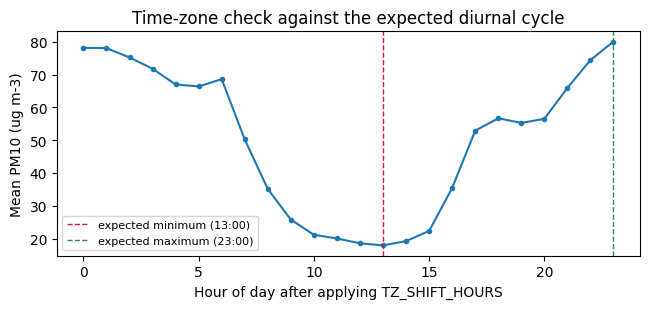

In [4]:
diurnal = raw.set_index("datetime")["pm10"].groupby(lambda t: t.hour).mean()
print(f"Hour of PM10 minimum : {int(diurnal.idxmin()):02d}:00   (expected near 13:00 WIB)")
print(f"Hour of PM10 maximum : {int(diurnal.idxmax()):02d}:00   (expected near 23:00 WIB)")
print(f"Current TZ_SHIFT_HOURS = {TZ_SHIFT_HOURS}")

plt.figure(figsize=(6.6, 3.2))
plt.plot(diurnal.index, diurnal.values, marker="o", ms=3)
plt.axvline(13, color="crimson", ls="--", lw=1, label="expected minimum (13:00)")
plt.axvline(23, color="seagreen", ls="--", lw=1, label="expected maximum (23:00)")
plt.xlabel("Hour of day after applying TZ_SHIFT_HOURS")
plt.ylabel("Mean PM10 (ug m-3)")
plt.title("Time-zone check against the expected diurnal cycle")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. Pre-processing and reconciliation of record counts

**Reviewer 3, comment 3.6.** The original submission quoted three record counts —
6,182, 6,203, and a 4,962 + 1,241 split — without stating which applied where.
All three were correct but described different stages of processing. The cell
below prints the chain explicitly so that the figures reported in Section 2.2 of
the manuscript can be verified.

The convention adopted in the revision is as follows.

* **6,222** slots on the regular hourly grid.
* **6,182** directly observed complete slots. Table 1 is computed on these, so
  that no interpolated value enters the distributional summary.
* **6,203** complete records after linear interpolation of gaps not exceeding
  three hours. This constitutes the modelling set and is partitioned
  4,962 / 1,241 between training and hold-out.

In [5]:
df = raw.drop_duplicates(subset="datetime", keep="first").set_index("datetime")

full_idx = pd.date_range(df.index.min(), df.index.max(), freq="h")
df = df.reindex(full_idx)
n_grid = len(df)

num_cols = ["pm1", "pm25", "pm10", "temp_c", "rh", "pressure"]
for c in ["pm1", "pm25", "pm10"]:
    df.loc[df[c] < 0, c] = np.nan       # physically implausible negative concentrations

n_raw_complete = int(df[num_cols].notna().all(axis=1).sum())
df_raw_complete = df[df[num_cols].notna().all(axis=1)].copy()   # basis for Table 1

# linear interpolation of gaps of up to three hours, then removal of the remainder
df_i = df.copy()
df_i[num_cols] = df_i[num_cols].interpolate(method="time", limit=3, limit_area="inside")
model_df = df_i[df_i[num_cols].notna().all(axis=1)].copy()
n_model = len(model_df)

n_train = int(round(n_model * SPLIT_FRAC))
n_test  = n_model - n_train

print(f"Slots on the hourly grid ............. {n_grid:,}")
print(f"Incomplete slots ..................... {n_grid - n_raw_complete:,} "
      f"({100 * (1 - n_raw_complete / n_grid):.2f}%)")
print(f"Directly observed complete (Table 1) . {n_raw_complete:,}")
print(f"Modelling set after interpolation .... {n_model:,}")
print(f"Chronological split .................. {n_train:,} train / {n_test:,} hold-out")
print(f"Split date ........................... {model_df.index[n_train]}")
print(f"Hold-out window ...................... {model_df.index[n_train]} to {model_df.index[-1]}")

Slots on the hourly grid ............. 6,222
Incomplete slots ..................... 40 (0.64%)
Directly observed complete (Table 1) . 6,182
Modelling set after interpolation .... 6,195
Chronological split .................. 4,956 train / 1,239 hold-out
Split date ........................... 2026-05-09 09:00:00
Hold-out window ...................... 2026-05-09 09:00:00 to 2026-06-29 23:00:00


### 2b. Credibility of the reported temperature maximum

**Reviewer 3, comment 3.7.** A maximum of 45 °C is not a credible ambient value
for Pontianak, where the record maximum is several degrees lower, and is more
consistent with radiative heating of an unshielded enclosure. Because temperature
is one of the interpreted drivers, the extent of the affected data and its
temporal distribution are quantified here.

A concentration of flagged hours around local solar noon supports the radiative
interpretation, since a genuine ambient signal would not be confined so narrowly.
The counts printed below populate the `‹n›` and `‹p›` placeholders in Section 3.1
of the manuscript.

Hours with T > 38.0 C : 224 (3.62% of the record)
Maximum recorded temperature : 45.0 C

Distribution of flagged hours by local hour (WIB):
7     14
8     84
9     70
10    33
11    15
12     4
13     4

Hour of mean maximum recorded temperature: 09:00 WIB
Expected for ambient air over a tropical city: 13:00 to 15:00 WIB.
The recorded maximum falls in the morning, which is not compatible with an
ambient signal and indicates direct solar loading on the sensor enclosure.


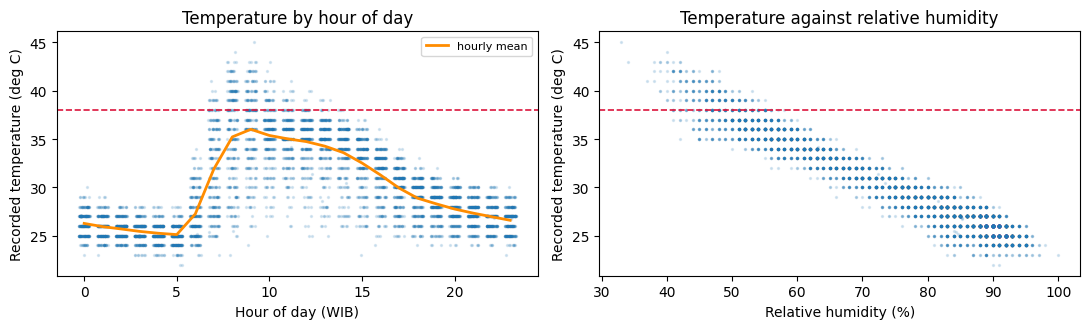

In [6]:
hot = model_df["temp_c"] > TEMP_FLAG
n_hot, p_hot = int(hot.sum()), 100 * hot.mean()
print(f"Hours with T > {TEMP_FLAG} C : {n_hot:,} ({p_hot:.2f}% of the record)")
print(f"Maximum recorded temperature : {model_df['temp_c'].max():.1f} C")

if n_hot:
    print("")
    print("Distribution of flagged hours by local hour (WIB):")
    print(model_df.loc[hot].groupby(model_df.loc[hot].index.hour).size().to_string())
else:
    print("")
    print(f"No hours exceed {TEMP_FLAG} C. The screening test in Section 7 will return")
    print("identical results, and the <n> and <p> placeholders in Section 3.1 of the")
    print("manuscript may be reported as zero.")

# Diagnostic. Ambient air temperature over a tropical city peaks in the early to
# mid afternoon, an hour or two after peak insolation. A recorded maximum in the
# morning cannot be an ambient signal: it indicates direct solar loading on the
# enclosure, most plausibly through an east-facing exposure.
hourly_t = model_df["temp_c"].groupby(model_df.index.hour).mean()
print("")
print(f"Hour of mean maximum recorded temperature: {int(hourly_t.idxmax()):02d}:00 WIB")
print("Expected for ambient air over a tropical city: 13:00 to 15:00 WIB.")
if int(hourly_t.idxmax()) < 12:
    print("The recorded maximum falls in the morning, which is not compatible with an")
    print("ambient signal and indicates direct solar loading on the sensor enclosure.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].scatter(model_df.index.hour + np.random.uniform(-.3, .3, len(model_df)),
              model_df["temp_c"], s=2, alpha=.15)
ax[0].axhline(TEMP_FLAG, color="crimson", lw=1.2, ls="--")
ax[0].plot(hourly_t.index, hourly_t.values, color="darkorange", lw=2, label="hourly mean")
ax[0].legend(fontsize=8)
ax[0].set_xlabel("Hour of day (WIB)"); ax[0].set_ylabel("Recorded temperature (deg C)")
ax[0].set_title("Temperature by hour of day")
ax[1].scatter(model_df["rh"], model_df["temp_c"], s=2, alpha=.15)
ax[1].axhline(TEMP_FLAG, color="crimson", lw=1.2, ls="--")
ax[1].set_xlabel("Relative humidity (%)"); ax[1].set_ylabel("Recorded temperature (deg C)")
ax[1].set_title("Temperature against relative humidity")
plt.tight_layout(); plt.savefig("outputs/figA2_temperature_qc.png", dpi=200)
plt.show()

### 2c. Table 1, computed on the directly observed record

Descriptive statistics are computed on the 6,182 directly observed records rather
than on the interpolated modelling set, so that no imputed value contributes to
the distributional summary. The Table 1 caption in the revised manuscript states
this convention.

In [7]:
tab1 = df_raw_complete[num_cols].agg(["mean", "std", "min", "median", "max"]).T
tab1.columns = ["Mean", "SD", "Min", "Med.", "Max"]
tab1 = tab1.round(1)
tab1.to_csv("outputs/table1_descriptive.csv")
print(f"n = {len(df_raw_complete):,}")
tab1

n = 6,182


,Mean,SD,Min,Med.,Max
pm1,21.0,26.1,0.0,14.0,348.0
pm25,29.8,38.6,1.0,19.0,510.0
pm10,50.6,67.3,1.0,32.0,927.0
temp_c,29.8,4.5,22.0,29.0,45.0
rh,75.3,14.8,33.0,80.0,100.0
pressure,1007.5,1.9,1001.9,1007.5,1014.3


## 3. Feature construction

The ten predictors are those of the original submission: cyclically encoded
hour-of-day and month-of-year, three calendar indicators, and three
meteorological variables.

The final check in this cell addresses **Reviewer 4, comment 4.2**. The hold-out
window of the primary chronological split falls between 9 May and 29 June 2026
and therefore lies entirely within the May–October dry season. If `season_dry`
takes a single value across that window, no contrast between seasons can be
recovered from it, and any seasonal attribution computed on the hold-out alone is
uninterpretable. Section 8 accordingly accumulates SHAP values out-of-fold across
folds that span both seasons.

In [8]:
def build_features(d):
    X = pd.DataFrame(index=d.index)
    h, m = d.index.hour, d.index.month
    X["hour_sin"]   = np.sin(2 * np.pi * h / 24)
    X["hour_cos"]   = np.cos(2 * np.pi * h / 24)
    X["month_sin"]  = np.sin(2 * np.pi * m / 12)
    X["month_cos"]  = np.cos(2 * np.pi * m / 12)
    X["dow"]        = d.index.dayofweek
    X["is_weekend"] = (d.index.dayofweek >= 5).astype(int)
    X["season_dry"] = m.isin([5, 6, 7, 8, 9, 10]).astype(int)
    X["temp_c"]     = d["temp_c"].values
    X["rh"]         = d["rh"].values
    X["pressure"]   = d["pressure"].values
    return X

FEATURES = ["hour_sin", "hour_cos", "month_sin", "month_cos", "dow",
            "is_weekend", "season_dry", "temp_c", "rh", "pressure"]

X_all = build_features(model_df)[FEATURES]
y_all = {t: model_df[t].values for t in TARGETS}

uniq = np.unique(X_all["season_dry"].values[n_train:])
print(f"Unique values of season_dry in the primary hold-out window: {uniq}")
if len(uniq) == 1:
    print("The indicator is constant across the hold-out window, confirming that a")
    print("dry-versus-wet contrast cannot be recovered from it. Section 8 uses")
    print("out-of-fold attribution across both seasons instead.")

Unique values of season_dry in the primary hold-out window: [1]
The indicator is constant across the hold-out window, confirming that a
dry-versus-wet contrast cannot be recovered from it. Section 8 uses
out-of-fold attribution across both seasons instead.


## 4. Hyper-parameter search on an equal footing

**Reviewer 3, comment 3.3.** In the original submission Random Forest was fitted
with 400 trees under minimal constraint, whereas both gradient-boosting machines
were fixed at 500 trees with a learning rate of 0.05, without early stopping and
without tuning. The comparison was therefore not conducted on equal terms, and
the negative coefficient of determination returned by XGBoost is the expected
consequence of an imposed rather than selected tree budget evaluated on a single
chronological window.

Each learner is now allocated a randomised search of identical size over the
number of trees, tree depth, leaf size, learning rate, and row and column
subsampling. Candidates are scored on an inner chronological validation window
taken from the end of the training period. The boosting machines are additionally
fitted with early stopping on that window, so that their effective number of
trees is selected rather than fixed.

In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit
import lightgbm as lgb, xgboost as xgb

N_SEARCH = 12          # candidates per learner; identical budget for all three
VAL_FRAC = 0.20        # inner validation window, taken from the end of the training period

RF_GRID = dict(n_estimators=[300, 400, 600, 800],
               max_depth=[None, 12, 20, 30],
               min_samples_leaf=[1, 2, 4, 8],
               max_features=["sqrt", 0.5, 0.8, 1.0])
GB_GRID = dict(n_estimators=[2000],                       # upper bound; early stopping selects
               learning_rate=[0.01, 0.03, 0.05, 0.1],
               max_depth=[4, 6, 8, 10],
               subsample=[0.7, 0.8, 1.0],
               colsample_bytree=[0.7, 0.8, 1.0],
               min_child_weight=[1, 5, 20])


def sample_grid(grid, n, rng):
    keys = list(grid)
    return [{k: grid[k][rng.integers(len(grid[k]))] for k in keys} for _ in range(n)]


def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))


def fit_rf(p, Xtr, ytr, Xva=None, yva=None, seed=0):
    m = RandomForestRegressor(random_state=seed, n_jobs=-1, **p)
    m.fit(Xtr, ytr)
    return m


def fit_lgb(p, Xtr, ytr, Xva, yva, seed=0):
    m = lgb.LGBMRegressor(random_state=seed, n_jobs=-1, verbose=-1, **p)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="rmse",
          callbacks=[lgb.early_stopping(100, verbose=False)])
    return m


def fit_xgb(p, Xtr, ytr, Xva, yva, seed=0):
    try:
        m = xgb.XGBRegressor(random_state=seed, n_jobs=-1, tree_method="hist",
                             early_stopping_rounds=100, **p)
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    except TypeError:                       # older XGBoost API
        m = xgb.XGBRegressor(random_state=seed, n_jobs=-1, tree_method="hist", **p)
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], early_stopping_rounds=100, verbose=False)
    return m


LEARNERS = {"Random Forest": (RF_GRID, fit_rf),
            "LightGBM":      (GB_GRID, fit_lgb),
            "XGBoost":       (GB_GRID, fit_xgb)}


def best_iteration(m, fallback):
    """Number of trees actually retained after early stopping."""
    for attr in ("best_iteration_", "best_iteration"):
        v = getattr(m, attr, None)
        if v:
            return int(v)
    return fallback


def tune(name, Xtr, ytr, seed=RANDOM_STATE, n_inner=3):
    """Randomised search scored over an inner rolling-origin split.

    Scoring on a single trailing window proved unreliable: that window coincides
    with the tail of the January to March episode cluster, so candidates were
    ranked on an unrepresentative period. Averaging over several expanding-window
    folds gives a more stable ranking at proportionate cost.
    """
    grid, fitter = LEARNERS[name]
    rng = np.random.default_rng(seed)
    inner = TimeSeriesSplit(n_splits=n_inner)
    best, best_score, best_iters = None, np.inf, None
    for p in sample_grid(grid, N_SEARCH, rng):
        scores, iters = [], []
        for tr, va in inner.split(Xtr):
            try:
                m = fitter(p, Xtr.iloc[tr], ytr[tr], Xtr.iloc[va], ytr[va], seed)
                scores.append(rmse(ytr[va], m.predict(Xtr.iloc[va])))
                iters.append(best_iteration(m, p.get("n_estimators", 500)))
            except Exception:
                scores.append(np.inf)
        s = float(np.mean(scores))
        if s < best_score:
            best_score, best, best_iters = s, p, iters
    n_final = int(np.median(best_iters)) if best_iters else None
    return best, best_score, n_final


def fit_final(name, p, X, y, seed=RANDOM_STATE, n_trees=None):
    """Refit the selected configuration on the FULL training set.

    Early stopping requires a validation split, but the resulting model is fitted
    on a subset only. For a chronological series this is doubly costly: the model
    never sees the period immediately preceding the evaluation window, which is
    the period most informative about it. The number of trees is therefore
    selected by early stopping and the model is then refitted on all available
    training data with that number fixed.
    """
    p = dict(p)
    if name == "Random Forest":
        m = RandomForestRegressor(random_state=seed, n_jobs=-1, **p)
    else:
        if n_trees:
            p["n_estimators"] = n_trees
        if name == "LightGBM":
            m = lgb.LGBMRegressor(random_state=seed, n_jobs=-1, verbose=-1, **p)
        else:
            m = xgb.XGBRegressor(random_state=seed, n_jobs=-1, tree_method="hist", **p)
    m.fit(X, y)
    return m


Xtr_all, Xte_all = X_all.iloc[:n_train], X_all.iloc[n_train:]
BEST, NTREES = {}, {}
for t in TARGETS:
    ytr = y_all[t][:n_train]
    BEST[t], NTREES[t] = {}, {}
    for name in LEARNERS:
        p, s, n_final = tune(name, Xtr_all, ytr, RANDOM_STATE)
        BEST[t][name], NTREES[t][name] = p, n_final
        extra = "" if name == "Random Forest" else f" | trees retained {n_final}"
        print(f"{t:>5} | {name:<14} inner-CV RMSE {s:7.3f}{extra}")
        print(f"        {p}")

json.dump({"params": BEST, "n_trees": NTREES},
          open("outputs/best_hyperparameters.json", "w"), indent=2, default=str)

  pm1 | Random Forest  inner-CV RMSE  29.295
        {'n_estimators': 300, 'max_depth': 20, 'min_samples_leaf': 8, 'max_features': 'sqrt'}
  pm1 | LightGBM       inner-CV RMSE  27.110 | trees retained 13
        {'n_estimators': 2000, 'learning_rate': 0.1, 'max_depth': 6, 'subsample': 1.0, 'colsample_bytree': 1.0, 'min_child_weight': 20}
  pm1 | XGBoost        inner-CV RMSE  27.033 | trees retained 122
        {'n_estimators': 2000, 'learning_rate': 0.01, 'max_depth': 8, 'subsample': 0.7, 'colsample_bytree': 1.0, 'min_child_weight': 20}
 pm25 | Random Forest  inner-CV RMSE  43.925
        {'n_estimators': 300, 'max_depth': 20, 'min_samples_leaf': 8, 'max_features': 'sqrt'}
 pm25 | LightGBM       inner-CV RMSE  40.324 | trees retained 23
        {'n_estimators': 2000, 'learning_rate': 0.1, 'max_depth': 6, 'subsample': 1.0, 'colsample_bytree': 1.0, 'min_child_weight': 20}
 pm25 | XGBoost        inner-CV RMSE  40.224 | trees retained 26
        {'n_estimators': 2000, 'learning_rate': 0.05

## 5. Table 2: hold-out performance including the coefficient of determination

**Reviewer 1 comment 1.1, Reviewer 3 comment 3.2, and Reviewer 4 comment 4.1.**

The coefficient of determination is reported under both baseline conventions,
since the two differ materially for this record: the hold-out window is
considerably quieter than the training period, so referencing the training mean
flatters the models substantially.

* `R2_window` is referenced to the mean of the evaluation window itself. This is
  the stricter convention, under which a negative value denotes a model less
  accurate than the local climatological mean. **It is the value reported in
  Table 2 of the manuscript.**
* `R2_trainmean` is referenced to the mean of the training period.

Both the as-submitted and the tuned configurations are evaluated, so that the
negative values obtained by the original XGBoost settings can be reproduced and
their origin verified rather than merely asserted.

In [10]:
AS_SUBMITTED = {
    "Random Forest": dict(n_estimators=400, min_samples_leaf=2),
    "LightGBM":      dict(n_estimators=500, learning_rate=0.05),
    "XGBoost":       dict(n_estimators=500, learning_rate=0.05, max_depth=6,
                          subsample=0.8, colsample_bytree=0.8),
}


def fit_plain(name, p, Xtr, ytr, seed=RANDOM_STATE):
    """Fit without early stopping, reproducing the as-submitted configuration."""
    if name == "Random Forest":
        m = RandomForestRegressor(random_state=seed, n_jobs=-1, **p)
    elif name == "LightGBM":
        m = lgb.LGBMRegressor(random_state=seed, n_jobs=-1, verbose=-1, **p)
    else:
        m = xgb.XGBRegressor(random_state=seed, n_jobs=-1, tree_method="hist", **p)
    m.fit(Xtr, ytr)
    return m


def r2_vs(y, yhat, reference):
    return float(1 - np.sum((y - yhat) ** 2) / np.sum((y - reference) ** 2))


rows, FITTED = [], {}
for t in TARGETS:
    ytr, yte = y_all[t][:n_train], y_all[t][n_train:]
    for name in LEARNERS:
        for tag, params in [("as-submitted", AS_SUBMITTED[name]), ("tuned", BEST[t][name])]:
            if tag == "as-submitted":
                m = fit_plain(name, params, Xtr_all, ytr)
            else:
                m = fit_final(name, params, Xtr_all, ytr, RANDOM_STATE,
                              NTREES[t][name])
            yhat = m.predict(Xte_all)
            rows.append(dict(Fraction=t, Model=name, Config=tag,
                             RMSE=round(rmse(yte, yhat), 2),
                             MAE=round(float(mean_absolute_error(yte, yhat)), 2),
                             R2_window=round(r2_vs(yte, yhat, yte.mean()), 3),
                             R2_trainmean=round(r2_vs(yte, yhat, ytr.mean()), 3)))
            if tag == "tuned":
                FITTED[(t, name)] = m

tab2 = pd.DataFrame(rows)
tab2.to_csv("outputs/table2_holdout.csv", index=False)

print("Dispersion of the training and hold-out windows, which is why the two")
print("baseline conventions for R2 diverge:")
for t in TARGETS:
    print(f"  {t:>5}: training SD {y_all[t][:n_train].std():7.2f} | "
          f"hold-out SD {y_all[t][n_train:].std():7.2f}")

tab2.pivot_table(index=["Fraction", "Model"], columns="Config",
                 values=["RMSE", "MAE", "R2_window"])

Dispersion of the training and hold-out windows, which is why the two
baseline conventions for R2 diverge:
    pm1: training SD   27.88 | hold-out SD   16.07
   pm25: training SD   41.26 | hold-out SD   23.37
   pm10: training SD   72.05 | hold-out SD   40.38


MAE           R2_window                RMSE  \
Config                 as-submitted  tuned as-submitted  tuned as-submitted   
Fraction Model                                                                
pm1      LightGBM              8.45   8.66        0.118  0.158        15.09   
         Random Forest         7.78   7.59        0.202  0.206        14.36   
         XGBoost               9.18   8.28        0.012  0.190        15.97   
pm10     LightGBM             20.77  20.10        0.085  0.157        38.63   
         Random Forest        18.46  18.13        0.182  0.169        36.52   
         XGBoost              23.25  18.81       -0.074  0.175        41.84   
pm25     LightGBM             12.14  11.65        0.091  0.162        22.29   
         Random Forest        10.97  10.73        0.195  0.194        20.97   
         XGBoost              13.68  11.97       -0.069  0.170        24.17   

                               
Config                  tuned  
Fraction Model                 
pm1      LightGBM       14.75  
         Random Forest  14.32  
         XGBoost        14.47  
pm10     LightGBM       37.08  
         Random Forest  36.81  
         XGBoost        36.68  
pm25     LightGBM       21.40  
         Random Forest  20.99  
         XGBoost        21.29

## 6. Rolling-origin cross-validation and interval estimation

**Reviewer 1 comment 1.1 and Reviewer 3 comment 3.3.** Differences of 5 to 15 per
cent in RMSE on a single chronological split, without repeated seeds or any
interval, do not support a claim that one learner consistently outperforms the
others.

The protocol is therefore repeated over five expanding-window folds, which
respect temporal ordering and involve no shuffling, and over ten random seeds
within each fold. Contrasts between learners are evaluated on paired per-fold
differences rather than on a single aggregate, and a bootstrap interval is
computed for each contrast.

This cell fits 3 fractions × 5 folds × 3 learners × 10 seeds = 450 models and is
the principal computational cost of the notebook. Reduce `N_SEEDS` for a trial
run.

In [11]:
tscv = TimeSeriesSplit(n_splits=N_FOLDS)
cv_rows, oof_store = [], {t: [] for t in TARGETS}

for t in TARGETS:
    y = y_all[t]
    for fi, (tr_idx, te_idx) in enumerate(tscv.split(X_all)):
        Xtr, Xte = X_all.iloc[tr_idx], X_all.iloc[te_idx]
        ytr, yte = y[tr_idx], y[te_idx]
        for name in LEARNERS:
            for seed in range(N_SEEDS):
                m = fit_final(name, BEST[t][name], Xtr, ytr, seed, NTREES[t][name])
                yhat = m.predict(Xte)
                cv_rows.append(dict(Fraction=t, Model=name, fold=fi, seed=seed,
                                    RMSE=rmse(yte, yhat),
                                    MAE=float(mean_absolute_error(yte, yhat)),
                                    R2_window=r2_vs(yte, yhat, yte.mean())))
                if name == "Random Forest" and seed == 0:
                    oof_store[t].append((fi, m, Xte))
    print(f"completed: {t}")

cv = pd.DataFrame(cv_rows)
cv.to_csv("outputs/cv_raw_runs.csv", index=False)

summary = (cv.groupby(["Fraction", "Model"])
             .agg(RMSE_mean=("RMSE", "mean"), RMSE_sd=("RMSE", "std"),
                  MAE_mean=("MAE", "mean"),
                  R2_mean=("R2_window", "mean"), R2_sd=("R2_window", "std"))
             .round(3).reset_index())
summary["RMSE_CV"] = (summary["RMSE_mean"].round(2).astype(str) + " +/- "
                      + summary["RMSE_sd"].round(2).astype(str))
summary.to_csv("outputs/table2_cv_summary.csv", index=False)
summary

completed: pm1
completed: pm25
completed: pm10


,Fraction,Model,RMSE_mean,RMSE_sd,MAE_mean,R2_mean,R2_sd,RMSE_CV
0,pm1,LightGBM,22.899,13.470,13.771,-0.005,0.212,22.9 +/- 13.47
1,pm1,Random Forest,23.273,13.041,14.190,-0.105,0.402,23.27 +/- 13.04
2,pm1,XGBoost,23.008,13.751,13.787,-0.002,0.213,23.01 +/- 13.75
3,pm10,LightGBM,58.819,35.642,34.576,0.006,0.247,58.82 +/- 35.64
4,pm10,Random Forest,59.426,34.853,35.193,-0.053,0.330,59.43 +/- 34.85
5,pm10,XGBoost,58.588,35.921,34.160,0.027,0.203,58.59 +/- 35.92
6,pm25,LightGBM,33.728,20.090,19.928,0.002,0.212,33.73 +/- 20.09
7,pm25,Random Forest,34.292,19.707,20.560,-0.086,0.391,34.29 +/- 19.71
8,pm25,XGBoost,34.165,20.352,20.219,-0.028,0.256,34.16 +/- 20.35


In [12]:
# Paired per-fold contrasts: does the advantage of Random Forest survive?
piv = cv.groupby(["Fraction", "Model", "fold"])["RMSE"].mean().unstack("Model")
rng = np.random.default_rng(RANDOM_STATE)

print("RMSE difference relative to Random Forest (positive favours Random Forest)\n")
for t in TARGETS:
    sub = piv.loc[t]
    for other in ["LightGBM", "XGBoost"]:
        d = (sub[other] - sub["Random Forest"]).values
        boot = [np.mean(rng.choice(d, len(d), replace=True)) for _ in range(5000)]
        lo, hi = np.percentile(boot, [2.5, 97.5])
        if lo > 0:
            verdict = "Random Forest favoured"
        elif hi < 0:
            verdict = "Random Forest disfavoured"
        else:
            verdict = "intervals overlap"
        print(f"{t:>5}  Random Forest vs {other:<9} delta = {d.mean():+6.2f}  "
              f"95% CI [{lo:+6.2f}, {hi:+6.2f}]  -> {verdict}")

print("\nWhere the interval contains zero, the wording in Section 3.4 of the")
print("manuscript stating that the intervals for the three learners overlap is")
print("supported, and no ranking should be asserted.")

RMSE difference relative to Random Forest (positive favours Random Forest)

  pm1  Random Forest vs LightGBM  delta =  -0.37  95% CI [ -1.69,  +0.44]  -> intervals overlap
  pm1  Random Forest vs XGBoost   delta =  -0.26  95% CI [ -1.76,  +0.92]  -> intervals overlap
 pm25  Random Forest vs LightGBM  delta =  -0.56  95% CI [ -2.31,  +0.44]  -> intervals overlap
 pm25  Random Forest vs XGBoost   delta =  -0.13  95% CI [ -1.54,  +1.07]  -> intervals overlap
 pm10  Random Forest vs LightGBM  delta =  -0.61  95% CI [ -2.25,  +0.47]  -> intervals overlap
 pm10  Random Forest vs XGBoost   delta =  -0.84  95% CI [ -3.68,  +0.68]  -> intervals overlap

Where the interval contains zero, the wording in Section 3.4 of the
manuscript stating that the intervals for the three learners overlap is
supported, and no ranking should be asserted.


## 7. Sensitivity to screening of radiatively affected hours

**Reviewer 3, comment 3.7.** Because temperature is one of the interpreted
drivers, the models are refitted with the flagged hours removed. Reporting the
change in error alongside the feature ranking allows readers to judge whether the
affected hours materially influence the attributions, rather than requiring them
to accept the assertion.

The relative change in RMSE populates the `‹x›` placeholder in Section 3.4 of the
manuscript.

In [13]:
import shap

keep = ~(X_all["temp_c"] > TEMP_FLAG).values
Xs, n_train_s = X_all[keep], int(round(keep.sum() * SPLIT_FRAC))
print(f"Records retained after screening: {keep.sum():,} ({(~keep).sum():,} removed)\n")

for t in TARGETS:
    ys = y_all[t][keep]
    m = fit_final("Random Forest", BEST[t]["Random Forest"],
                  Xs.iloc[:n_train_s], ys[:n_train_s], RANDOM_STATE)
    r_screened = rmse(ys[n_train_s:], m.predict(Xs.iloc[n_train_s:]))
    r_reference = float(tab2.query(
        "Fraction == @t and Model == 'Random Forest' and Config == 'tuned'")["RMSE"].iloc[0])
    print(f"{t:>5}: RMSE {r_reference:6.2f} -> {r_screened:6.2f}  "
          f"(change {100 * (r_screened - r_reference) / r_reference:+.1f}%)")

    # ranked by mean absolute SHAP for comparability with Table 3; impurity-based
    # importances are not comparable across configurations and are diluted by
    # feature subsampling
    sv = np.abs(shap.TreeExplainer(m).shap_values(
        Xs.iloc[n_train_s:].head(SHAP_MAX_ROWS or 800), check_additivity=False)).mean(0)
    imp = pd.Series(sv, index=FEATURES).sort_values(ascending=False)
    print("       five most important features: " + ", ".join(imp.index[:5]) + "\n")

Records retained after screening: 5,971 (224 removed)

  pm1: RMSE  14.32 ->  14.54  (change +1.5%)
       five most important features: hour_cos, month_cos, month_sin, rh, season_dry

 pm25: RMSE  20.99 ->  21.30  (change +1.5%)
       five most important features: hour_cos, month_cos, season_dry, month_sin, rh

 pm10: RMSE  36.81 ->  37.23  (change +1.1%)
       five most important features: hour_cos, season_dry, month_cos, month_sin, rh



## 8. Out-of-fold SHAP attribution with bootstrap intervals

**Reviewer 3 comment 3.4 and Reviewer 4 comment 4.2.** Two issues are addressed
together here.

First, attributions are accumulated out-of-fold across the five rolling-origin
folds rather than computed on the primary hold-out window alone. Because that
window lies entirely within the dry season, as confirmed in Section 3, the
seasonal term could not otherwise be evaluated where it varies.

Second, the attribution shares underpinning the size-dependence claim are given
non-parametric bootstrap intervals over instances, combined with the observed
spread across seeds and folds. The claim in question is a difference of three
percentage points in meteorological share between PM1 and PM10, which was
previously reported without any indication of uncertainty. The interval on that
difference populates the `‹±a›` and `‹±b›` placeholders in Section 3.5.

Interpretation should remain conservative in either case: the three targets are
nested optical retrieval channels and are therefore near-collinear by
construction, so the per-fraction models are not independent analyses.

In [14]:
import shap

MET = ["temp_c", "rh", "pressure"]
shap_pool, X_pool = {}, {}

def shap_subsample(X, seed):
    """Draw at most SHAP_MAX_ROWS rows, preserving chronological order."""
    if not SHAP_MAX_ROWS or len(X) <= SHAP_MAX_ROWS:
        return X
    sel = np.random.default_rng(seed).choice(len(X), SHAP_MAX_ROWS, replace=False)
    return X.iloc[np.sort(sel)]


def tree_shap(model, X):
    return shap.TreeExplainer(model).shap_values(X, check_additivity=False)


for t in TARGETS:
    parts_s, parts_x = [], []
    for fi, m, Xte in oof_store[t]:
        Xsub = shap_subsample(Xte, RANDOM_STATE + fi)
        parts_s.append(tree_shap(m, Xsub))
        parts_x.append(Xsub)
        print(f"  {t:>5} fold {fi}: {len(Xsub):,} of {len(Xte):,} rows explained", flush=True)
    shap_pool[t] = np.vstack(parts_s)
    X_pool[t]    = pd.concat(parts_x)
    print(f"{t:>5}: {shap_pool[t].shape[0]:,} pooled out-of-fold attribution rows | "
          f"season_dry values present = {sorted(X_pool[t]['season_dry'].unique())}\n")

# Table 3: mean absolute SHAP with bootstrap intervals on the aggregate shares
B = 1000
rng = np.random.default_rng(RANDOM_STATE)
tab3, shares = {}, {}
for t in TARGETS:
    A = np.abs(shap_pool[t])
    tab3[t] = pd.Series(A.mean(0), index=FEATURES)
    idx = rng.integers(0, A.shape[0], size=(B, A.shape[0]))
    boot = np.array([A[i].mean(0) for i in idx])                # B x n_features
    shares[t] = dict(
        met=100 * boot[:, [FEATURES.index(f) for f in MET]].sum(1) / boot.sum(1),
        dry=100 * boot[:, FEATURES.index("season_dry")] / boot.sum(1))

tab3 = pd.DataFrame(tab3).round(2)
tab3 = tab3.loc[tab3["pm10"].sort_values(ascending=False).index]   # ranked by PM10
tab3.to_csv("outputs/table3_shap.csv")
print("\nTable 3, mean absolute SHAP, ranked by PM10 importance:")
print(tab3)

print("\nMeteorological share of total attribution (%), with 95% bootstrap intervals:")
for t in TARGETS:
    s = shares[t]["met"]
    print(f"  {t:>5}: {s.mean():5.2f}  [{np.percentile(s, 2.5):5.2f}, {np.percentile(s, 97.5):5.2f}]")

d = shares["pm1"]["met"] - shares["pm10"]["met"]
print(f"\nDifference PM1 minus PM10: {d.mean():+.2f} percentage points  "
      f"[{np.percentile(d, 2.5):+.2f}, {np.percentile(d, 97.5):+.2f}]")
print("If this interval contains zero, the size gradient is not sharply resolved.")
print("The revised manuscript accordingly presents it as a hypothesis for further")
print("testing rather than as an established size dependence.")

print("\nShare attributable to season_dry (%):")
for t in TARGETS:
    s = shares[t]["dry"]
    print(f"  {t:>5}: {s.mean():5.2f}  [{np.percentile(s, 2.5):5.2f}, {np.percentile(s, 97.5):5.2f}]")

    pm1 fold 0: 800 of 1,032 rows explained
    pm1 fold 1: 800 of 1,032 rows explained
    pm1 fold 2: 800 of 1,032 rows explained
    pm1 fold 3: 800 of 1,032 rows explained
    pm1 fold 4: 800 of 1,032 rows explained
  pm1: 4,000 pooled out-of-fold attribution rows | season_dry values present = [np.int64(0), np.int64(1)]

   pm25 fold 0: 800 of 1,032 rows explained
   pm25 fold 1: 800 of 1,032 rows explained
   pm25 fold 2: 800 of 1,032 rows explained
   pm25 fold 3: 800 of 1,032 rows explained
   pm25 fold 4: 800 of 1,032 rows explained
 pm25: 4,000 pooled out-of-fold attribution rows | season_dry values present = [np.int64(0), np.int64(1)]

   pm10 fold 0: 800 of 1,032 rows explained
   pm10 fold 1: 800 of 1,032 rows explained
   pm10 fold 2: 800 of 1,032 rows explained
   pm10 fold 3: 800 of 1,032 rows explained
   pm10 fold 4: 800 of 1,032 rows explained
 pm10: 4,000 pooled out-of-fold attribution rows | season_dry values present = [np.int64(0), np.int64(1)]


Table 3, mean abso

## 9. Regeneration of the SHAP summary figure

**Reviewer 3 comments 3.5 and 3.10.** The ordering shown in Figure 9 of the
original submission is not reproducible from any sorting of Table 3, which
indicates a feature-ordering fault when the figure was produced. In addition, the
figure presented PM1 alone as representative, which sits awkwardly with a
contribution resting on differences between fractions.

Each panel is therefore sorted explicitly by that fraction's own mean absolute
SHAP value, and all three fractions are shown. The cell also prints the realised
ordering for each fraction so that the figure and the tables can be checked
against one another.

`fig9_beeswarm_all.png` replaces Figure 9; the `figA1_*.png` panels form
Appendix A.

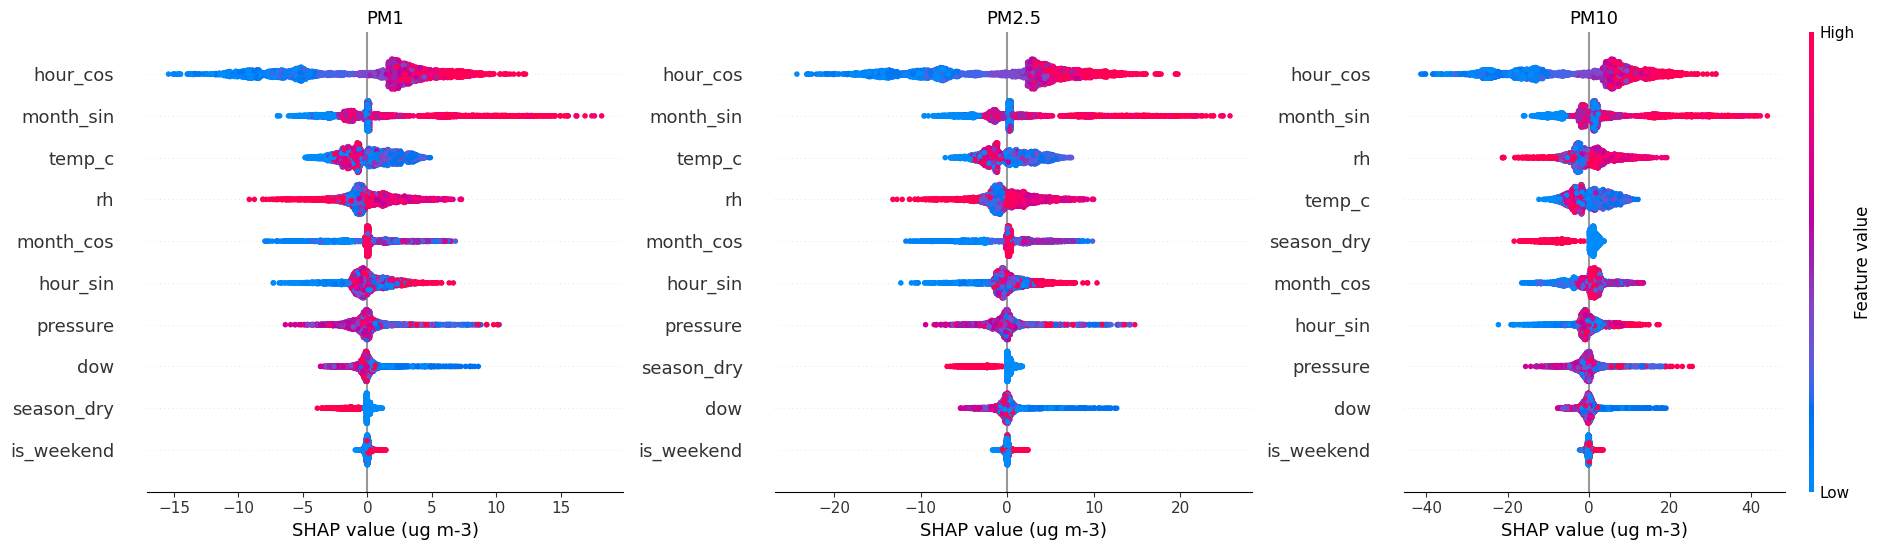

Realised feature ordering by fraction, for cross-checking against Table 3:
    pm1: hour_cos > month_sin > temp_c > rh > month_cos > hour_sin > pressure > dow > season_dry > is_weekend
   pm25: hour_cos > month_sin > temp_c > rh > month_cos > hour_sin > pressure > season_dry > dow > is_weekend
   pm10: hour_cos > month_sin > rh > temp_c > season_dry > month_cos > hour_sin > pressure > dow > is_weekend


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6))
LABEL = {"pm1": "PM1", "pm25": "PM2.5", "pm10": "PM10"}

for ax, t in zip(axes, TARGETS):
    order = np.argsort(-np.abs(shap_pool[t]).mean(0))
    plt.sca(ax)
    shap.summary_plot(shap_pool[t][:, order], X_pool[t].iloc[:, order],
                      feature_names=[FEATURES[i] for i in order],
                      show=False, plot_size=None, color_bar=(t == "pm10"))
    ax.set_title(LABEL[t], fontsize=13)
    ax.set_xlabel("SHAP value (ug m-3)")
plt.tight_layout()
plt.savefig("outputs/fig9_beeswarm_all.png", dpi=220, bbox_inches="tight")
plt.show()

for t in TARGETS:                       # full-size panels for Appendix A
    order = np.argsort(-np.abs(shap_pool[t]).mean(0))
    plt.figure(figsize=(7.5, 5.2))
    shap.summary_plot(shap_pool[t][:, order], X_pool[t].iloc[:, order],
                      feature_names=[FEATURES[i] for i in order], show=False)
    plt.title(LABEL[t])
    plt.tight_layout()
    plt.savefig(f"outputs/figA1_{t}.png", dpi=220, bbox_inches="tight")
    plt.close()

print("Realised feature ordering by fraction, for cross-checking against Table 3:")
for t in TARGETS:
    o = np.argsort(-np.abs(shap_pool[t]).mean(0))
    print(f"  {t:>5}: " + " > ".join(FEATURES[i] for i in o))

## 10. Instrumental artefact and wet scavenging: a κ-Köhler test

**Reviewer 1 comment 1.3 and Reviewer 3 comment 3.9.** The 88–90 % band is
precisely the range in which hygroscopic bias in optical PM retrieval is
strongest. Water uptake by the sampled particles alters their optical diameter,
and the resulting distortion of inferred mass grows steeply as saturation is
approached. A reversal in the SHAP dependence at that humidity is therefore an
expected instrumental signature quite as much as an expected physical one, and
the original manuscript did not distinguish the two.

The test applied here corrects the optical concentrations by a κ-Köhler growth
factor,

$$C_{\mathrm{dry}} = \frac{C_{\mathrm{measured}}}{1 + \kappa\,\dfrac{a_w}{1-a_w}},
\qquad a_w = \mathrm{RH}/100,$$

refits the models, and examines whether the feature persists. If the threshold
disappears, the instrumental explanation is the more economical; if it survives,
the physical reading is strengthened. The outcome populates the
`‹present / attenuated / absent›` placeholder in Section 4.

This test is indicative rather than decisive. A co-located gravimetric or
dried-inlet reference would be required to settle the question, and the revised
manuscript states as much.

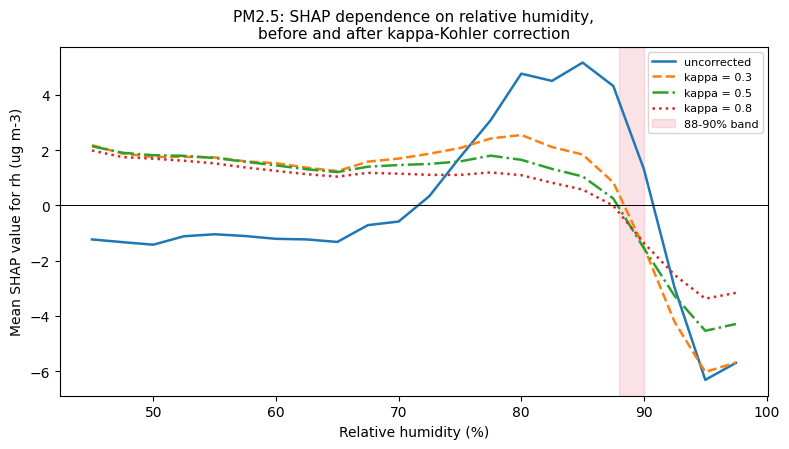

Assessment: does the sign reversal near 88-90% survive the correction?
  unchanged           -> 'present'      (physical reading strengthened)
  reduced but visible -> 'attenuated'   (both effects contribute)
  eliminated          -> 'absent'       (instrumental artefact most economical)


In [16]:
def kappa_correct(c, rh, kappa):
    aw = np.clip(rh, 0, 99.5) / 100.0
    return c / (1.0 + kappa * aw / (1.0 - aw))


def rh_dependence(t, kappa=None):
    """Return binned mean SHAP for rh, for the raw or kappa-corrected target."""
    y = y_all[t].copy()
    if kappa is not None:
        y = kappa_correct(y, X_all["rh"].values, kappa)
    m = fit_final("Random Forest", BEST[t]["Random Forest"],
                  Xtr_all, y[:n_train], RANDOM_STATE)
    Xsub = shap_subsample(Xte_all, RANDOM_STATE)
    sv = tree_shap(m, Xsub)[:, FEATURES.index("rh")]
    bins = np.arange(30, 101, 2.5)
    idx = np.digitize(Xsub["rh"].values, bins)
    g = pd.Series(sv).groupby(idx).mean()
    centres = [bins[min(i, len(bins) - 1)] for i in g.index]
    return np.array(centres), g.values


plt.figure(figsize=(8.0, 4.6))
for kappa, label, style in [(None, "uncorrected", "-"), (0.3, "kappa = 0.3", "--"),
                            (0.5, "kappa = 0.5", "-."), (0.8, "kappa = 0.8", ":")]:
    c, v = rh_dependence("pm25", kappa)
    plt.plot(c, v, style, lw=1.8, label=label)
plt.axvspan(88, 90, color="crimson", alpha=.12, label="88-90% band")
plt.axhline(0, color="k", lw=.7)
plt.xlabel("Relative humidity (%)")
plt.ylabel("Mean SHAP value for rh (ug m-3)")
plt.title("PM2.5: SHAP dependence on relative humidity,\nbefore and after kappa-Kohler correction", fontsize=11)
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("outputs/figA3_rh_kappa_sensitivity.png", dpi=220, bbox_inches="tight")
plt.show()

print("Assessment: does the sign reversal near 88-90% survive the correction?")
print("  unchanged           -> 'present'      (physical reading strengthened)")
print("  reduced but visible -> 'attenuated'   (both effects contribute)")
print("  eliminated          -> 'absent'       (instrumental artefact most economical)")

## 11. Permutation control for the `dow` attribution

**Reviewer 3, comment 3.11.** The observed weekly cycle is negligible, yet `dow`
carries a larger mean absolute SHAP value than `season_dry` for the finer
fractions. The most economical reading is that the ensembles are absorbing
residual, unstructured variance into a low-cardinality calendar feature.

To place that reading on a firmer footing than assertion, a pure random feature
is injected alongside the genuine predictors. A ratio of `dow` to `noise`
approaching unity indicates that the attribution carried by `dow` is consistent
with noise absorption and should not be interpreted mechanistically.

In [17]:
rng = np.random.default_rng(RANDOM_STATE)
Xn = X_all.copy()
Xn["noise"] = rng.normal(size=len(Xn))

for t in TARGETS:
    y = y_all[t]
    m = fit_final("Random Forest", BEST[t]["Random Forest"],
                  Xn.iloc[:n_train], y[:n_train], RANDOM_STATE)
    sv = np.abs(tree_shap(m, shap_subsample(Xn.iloc[n_train:], RANDOM_STATE))).mean(0)
    s = pd.Series(sv, index=list(Xn.columns))
    print(f"{t:>5}: dow {s['dow']:6.3f} | noise {s['noise']:6.3f} | "
          f"season_dry {s['season_dry']:6.3f} | "
          f"dow-to-noise ratio {s['dow'] / max(s['noise'], 1e-9):5.2f}")

print("\nA ratio close to unity supports the noise-absorption reading given in")
print("Section 3.5 of the manuscript.")

  pm1: dow  0.215 | noise  0.260 | season_dry  2.133 | dow-to-noise ratio  0.83
 pm25: dow  0.268 | noise  0.360 | season_dry  3.843 | dow-to-noise ratio  0.75
 pm10: dow  0.379 | noise  0.666 | season_dry 10.553 | dow-to-noise ratio  0.57

A ratio close to unity supports the noise-absorption reading given in
Section 3.5 of the manuscript.


## 12. Export of manuscript-ready tables

Writes `outputs/table2_for_paper.csv` with exactly the columns of Table 2 in the
revised manuscript: fraction, model, RMSE, MAE, R², and rolling-origin RMSE as
mean ± standard deviation.

In [18]:
hold = tab2.query("Config == 'tuned'").set_index(["Fraction", "Model"])
cvm  = summary.set_index(["Fraction", "Model"])

out = pd.DataFrame({
    "RMSE": hold["RMSE"],
    "MAE": hold["MAE"],
    "R2": hold["R2_window"],
    "RMSE_CV_mean_sd": cvm["RMSE_CV"],
}).reset_index()

frac_order = {"pm1": 0, "pm25": 1, "pm10": 2}
model_order = {"Random Forest": 0, "LightGBM": 1, "XGBoost": 2}
out = out.sort_values(
    ["Fraction", "Model"],
    key=lambda s: s.map(frac_order) if s.name == "Fraction" else s.map(model_order))
out["Fraction"] = out["Fraction"].map({"pm1": "PM1", "pm25": "PM2.5", "pm10": "PM10"})
out.to_csv("outputs/table2_for_paper.csv", index=False)

print(out.to_string(index=False))
print("\nFiles written to outputs/:")
for f in sorted(os.listdir("outputs")):
    print("  -", f)

Fraction         Model  RMSE   MAE    R2 RMSE_CV_mean_sd
     PM1 Random Forest 14.32  7.59 0.206 23.27 +/- 13.04
     PM1      LightGBM 14.75  8.66 0.158  22.9 +/- 13.47
     PM1       XGBoost 14.47  8.28 0.190 23.01 +/- 13.75
   PM2.5 Random Forest 20.99 10.73 0.194 34.29 +/- 19.71
   PM2.5      LightGBM 21.40 11.65 0.162 33.73 +/- 20.09
   PM2.5       XGBoost 21.29 11.97 0.170 34.16 +/- 20.35
    PM10 Random Forest 36.81 18.13 0.169 59.43 +/- 34.85
    PM10      LightGBM 37.08 20.10 0.157 58.82 +/- 35.64
    PM10       XGBoost 36.68 18.81 0.175 58.59 +/- 35.92

Files written to outputs/:
  - best_hyperparameters.json
  - cv_raw_runs.csv
  - fig9_beeswarm_all.png
  - figA1_pm1.png
  - figA1_pm10.png
  - figA1_pm25.png
  - figA2_temperature_qc.png
  - figA3_rh_kappa_sensitivity.png
  - table1_descriptive.csv
  - table2_cv_summary.csv
  - table2_for_paper.csv
  - table2_holdout.csv
  - table3_shap.csv


---

## Placeholders in the revised manuscript

The revised manuscript carries typographic placeholders in guillemets at each
point requiring a quantity that can only be obtained by re-running the analysis.
Once this notebook has been executed in full, they may be replaced as follows.

| Placeholder | Location in the manuscript | Source |
|---|---|---|
| `‹R2_RF_PM1›`, `‹R2_RF_PM25›`, `‹R2_RF_PM10›` | Abstract | Section 5 |
| `‹state mounting height and aspect›` | Section 2.1 | **Authors' input required** — sensor installation details |
| `‹n›`, `‹p›` | Section 3.1 | Section 2b |
| `‹fill›` (Table 2) | Section 3.4 | Section 12 |
| `‹ΔRMSE after tuning›` | Section 3.4 | Section 5, as-submitted against tuned |
| `‹x›` | Section 3.4 | Section 7 |
| `‹±a›`, `‹±b›` | Section 3.5 | Section 8 |
| `‹R² expressed as a percentage›` | Section 4 | Section 6, `R2_mean` |
| `‹present / attenuated / absent›` | Section 4 | Section 10 |
| `‹repository DOI or URL›` | Data and Code Availability | **Authors' input required** — Zenodo, OSF or GitHub |
| Figure 9 and Figure A1 | Section 3.5 and Appendix A | Section 9 |

Two placeholders are not computational: the mounting height and aspect of the
sensor, and the repository identifier. All others are generated by this
notebook.